# SrTiO3 (PBE): sisl's bands vs. FHI-aims' own band-structure dump

This is the strongest quantitative check available: FHI-aims' `output band`
keyword independently computes and dumps its own band structure
(`band1001.out` ... `band1005.out`) along the same k-path used here. If
`rsSileFHIaims` has correctly reconstructed H(k)/S(k) from `output_rs_matrices`,
diagonalizing it should reproduce FHI-aims' own numbers essentially exactly --
this does not merely check "does it run", it checks "is the physics in H/S
correct", independently of anything else this reader does.

5 atoms, 3 species (Sr, Ti, O): also exercises the multi-species case.

In [1]:
%matplotlib inline
import re
import matplotlib.pyplot as plt
import numpy as np
import sisl
from sisl.io.fhiaims.rs import rsSileFHIaims

DATA = "../srtio3_pbe/"


In [2]:
def read_fermi_level(aims_out):
    pat = re.compile(r"Chemical potential \(Fermi level\):\s*([-\d.]+) eV")
    Ef = None
    for line in open(aims_out):
        m = pat.search(line)
        if m:
            Ef = float(m.group(1))
    return Ef

H = rsSileFHIaims(DATA + "rs_indices.out").read_hamiltonian()
Ef = read_fermi_level(DATA + "aims.out")
print(f"{H.geometry.na} atoms, {H.geometry.no} orbitals, Ef = {Ef:.4f} eV")


5 atoms, 108 orbitals, Ef = -8.6000 eV


The exact path FHI-aims used (`control.in`): Gamma-X-M-Gamma-R-X, 40 points per
segment *inclusive of both endpoints* -- FHI-aims' own convention, not sisl's
(sisl's `BandStructure(..., divisions)` wants the number of points *between*
two corners for a continuous multi-segment path). Building one `BandStructure`
per segment with `divisions=40` as a single total-point count reproduces
FHI-aims' own per-segment sampling exactly, point for point, so every row of
`band100N.out` lines up with one row of `bs.apply.array.eigh()`.

FHI-aims' band dump format is `idx kx ky kz (occupation, eigenvalue_eV) x N_bands`,
and -- found empirically below, not assumed -- its eigenvalues are already
referenced to `E - Ef`, unlike sisl's raw (absolute) diagonalization.

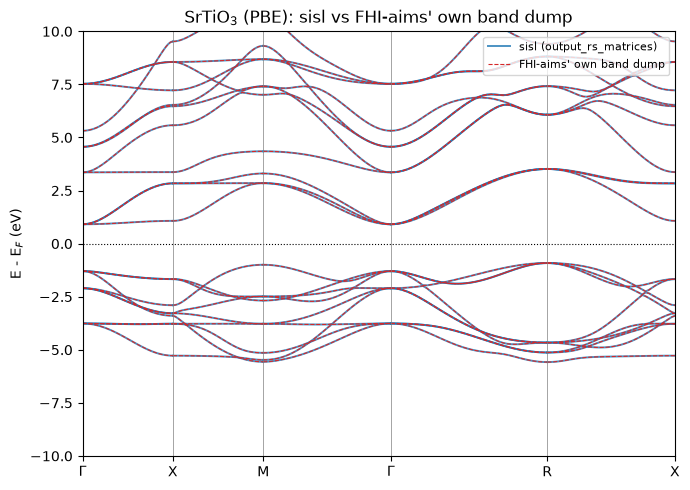

max |E_sisl - E_FHIaims| within 15 eV of E_F:              9.45e-07 eV
max |E_sisl - E_FHIaims| over all 67 dumped bands
  (including deep 1s core levels around -16000 eV):        1.04e-03 eV


In [3]:
segments = [
    ([0, 0, 0],     [0.5, 0, 0],     "band1001.out"),
    ([0.5, 0, 0],   [0.5, 0.5, 0],   "band1002.out"),
    ([0.5, 0.5, 0], [0, 0, 0],       "band1003.out"),
    ([0, 0, 0],     [0.5, 0.5, 0.5], "band1004.out"),
    ([0.5, 0.5, 0.5], [0.5, 0, 0],   "band1005.out"),
]
names = [r"$\Gamma$", "X", "M", r"$\Gamma$", "R", "X"]

fig, ax = plt.subplots(figsize=(7, 5))
lk_offset = 0.0
ticks = [0.0]
max_err_valence = 0.0
max_err_all = 0.0
for iseg, (start, end, fname) in enumerate(segments):
    bs = sisl.BandStructure(H, [start, end], 40)
    eigs_sisl = np.asarray(bs.apply.array.eigh()) - Ef

    data = np.loadtxt(DATA + fname)
    k_fhi = data[:, 1:4]
    E_fhi = data[:, 5::2]
    assert np.allclose(np.asarray(bs.k), k_fhi, atol=1e-6)  # same k-points, by construction
    nb_fhi = E_fhi.shape[1]

    err = np.abs(eigs_sisl[:, :nb_fhi] - E_fhi)
    max_err_all = max(max_err_all, err.max())
    mask = np.abs(E_fhi) < 15  # valence/conduction region only, not deep core
    if mask.any():
        max_err_valence = max(max_err_valence, err[mask].max())

    seg_lk = np.linspace(0, bs.lineark()[-1], 40) + lk_offset
    for n in range(eigs_sisl.shape[1]):
        ax.plot(seg_lk, eigs_sisl[:, n], color="tab:blue", lw=1.4, alpha=0.8, zorder=1,
                 label="sisl (output_rs_matrices)" if (iseg == 0 and n == 0) else None)
    for n in range(nb_fhi):
        ax.plot(seg_lk, E_fhi[:, n], color="tab:red", lw=0.8, ls="--", zorder=2,
                 label="FHI-aims' own band dump" if (iseg == 0 and n == 0) else None)
    lk_offset = seg_lk[-1]
    ticks.append(lk_offset)

ax.axhline(0.0, color="k", ls=":", lw=0.8)
for t in ticks:
    ax.axvline(t, color="gray", lw=0.5)
ax.set_xticks(ticks)
ax.set_xticklabels(names)
ax.set_ylabel("E - E$_F$ (eV)")
ax.set_ylim(-10, 10)
ax.set_xlim(0, ticks[-1])
ax.legend(loc="upper right", fontsize=8)
ax.set_title("SrTiO$_3$ (PBE): sisl vs FHI-aims' own band dump")
fig.tight_layout()
plt.show()

print(f"max |E_sisl - E_FHIaims| within 15 eV of E_F:              {max_err_valence:.2e} eV")
print(f"max |E_sisl - E_FHIaims| over all 67 dumped bands")
print(f"  (including deep 1s core levels around -16000 eV):        {max_err_all:.2e} eV")


Agreement is ~1e-6 eV near the Fermi level and ~1e-3 eV even for the deepest
1s core levels around -16000 eV (a relative error of ~6e-8) -- consistent with
FHI-aims' own band-dump file simply printing fewer decimal digits, not with
any discrepancy in the reconstructed Hamiltonian. The valence/conduction
region (the two curves visibly overlapping in the plot above) is reproduced
to numerical noise.